# MFPT Bearing Dataset Analysis  Member 1 - Vidyashankar T


### Report figures generated
1. **Fig. B1:** Inner race FFT across the available radial loads.
2. **Fig. B2:** Outer race FFT across the available radial loads.
3. **Fig. B3:** RMS vibration amplitude across radial loads, with the healthy baseline reference.


### Supplied dataset
- 3 healthy baseline records: 270 lb, 97.656 kHz, 6 s each.
- 7 inner-race records: 0, 50, 100, 150, 200, 250, and 300 lb; 48.828 kHz, 3 s each.
- 7 outer-race records: 25, 50, 100, 150, 200, 250, and 300 lb; 48.828 kHz, 3 s each.

## 1. Environment and MFPT input files


In [ ]:
from pathlib import Path
import sys
import zipfile
import shutil
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

# Create the MFPT working directory
EXTRACT_ROOT = Path("/content/MFPT_Analysis_Input")
MFPT_ROOT = EXTRACT_ROOT / "MFPT_Data"

if EXTRACT_ROOT.exists():
    shutil.rmtree(EXTRACT_ROOT)

MFPT_ROOT.mkdir(parents=True, exist_ok=True)

# Upload all five ZIP files together
from google.colab import files

uploaded = files.upload()

# Identify uploaded ZIP files
zip_files = [
    Path(name) for name in uploaded
    if name.endswith(".zip")
    and name.startswith("MFPT_Input_")
]

if len(zip_files) != 5:
    raise ValueError(
        f"Expected 5 dataset ZIP files, found {len(zip_files)}"
    )

# Extract all five ZIP files
for zip_path in zip_files:

    with zipfile.ZipFile(zip_path, "r") as zf:

        bad_file = zf.testzip()

        if bad_file:
            raise ValueError(f"Corrupted file: {bad_file}")

        zf.extractall(EXTRACT_ROOT)

    print("Extracted:", zip_path.name)

# Check that the Python module is present
module_path = MFPT_ROOT / "member1_signal_prep.py"

if not module_path.exists():
    raise FileNotFoundError(
        "member1_signal_prep.py is missing from the extracted files."
    )

# Import the corrected DSP module
sys.path.insert(0, str(MFPT_ROOT))

sys.modules.pop("member1_signal_prep", None)
importlib.invalidate_caches()

from member1_signal_prep import (
    load_mfpt_mat,
    preprocess_signal,
    single_sided_amplitude_spectrum,
    kinematic_fault_frequencies,
    MFPT_NICE
)

print("\nMFPT dataset setup completed!")
print("Dataset folder:", MFPT_ROOT)

Saving MFPT_Input_Baseline_3.zip to MFPT_Input_Baseline_3.zip
Saving MFPT_Input_Baseline_2.zip to MFPT_Input_Baseline_2.zip
Saving MFPT_Input_Baseline_1.zip to MFPT_Input_Baseline_1.zip
Saving MFPT_Input_OuterRace.zip to MFPT_Input_OuterRace.zip
Saving MFPT_Input_InnerRace.zip to MFPT_Input_InnerRace.zip
Extracted: MFPT_Input_Baseline_3.zip
Extracted: MFPT_Input_Baseline_2.zip
Extracted: MFPT_Input_Baseline_1.zip
Extracted: MFPT_Input_OuterRace.zip
Extracted: MFPT_Input_InnerRace.zip

MFPT dataset setup completed!
Dataset folder: /content/MFPT_Analysis_Input/MFPT_Data


## 2. Load and validate the 17 MFPT recordings

Each file is loaded using its MATLAB metadata. Any failed file is reported explicitly.

In [ ]:
mfpt_paths = sorted(
    [p for p in MFPT_ROOT.glob("*.mat")
     if p.name.lower().startswith(("baseline_", "innerracefault_", "outerracefault_"))],
    key=lambda p: p.name.lower()
)

print("MATLAB recordings found:", len(mfpt_paths))
if len(mfpt_paths) != 17:
    raise RuntimeError(f"Expected 17 recordings in the supplied dataset, found {len(mfpt_paths)}.")

mfpt_records = {}
load_errors = []
for path in mfpt_paths:
    try:
        rec = load_mfpt_mat(str(path))
        mfpt_records[path.name] = rec
    except Exception as exc:
        load_errors.append({"Filename": path.name, "Error": repr(exc)})

if load_errors:
    display(pd.DataFrame(load_errors))
    raise RuntimeError(f"{len(load_errors)} MFPT file(s) failed to load.")

print("Successfully loaded:", len(mfpt_records))

MATLAB recordings found: 17
Successfully loaded: 17


## 3. Recording metadata and load coverage

RMS and peak are calculated after removing the sample mean. They describe signal amplitude, they are not fault detection metrics.

In [ ]:
metadata_rows = []
for filename, rec in mfpt_records.items():
    x_demeaned, _, stats = preprocess_signal(rec.signal, normalization="none")
    metadata_rows.append({
        "Filename": filename,
        "Fault": rec.metadata["fault"],
        "Load_lb": float(rec.metadata["load_lbs"]),
        "Shaft_Rate_Hz": float(rec.metadata["shaft_rate_hz"]),
        "Shaft_RPM": float(rec.metadata["shaft_rpm"]),
        "Sampling_Rate_Hz": float(rec.sampling_rate),
        "Samples": int(len(rec.signal)),
        "Duration_s": float(rec.duration_seconds),
        "RMS_Demeaned": float(stats["rms_before_normalization"]),
        "Peak_Demeaned": float(stats["peak_before_normalization"]),
    })

mfpt_summary_df = pd.DataFrame(metadata_rows).sort_values(
    ["Fault", "Load_lb", "Filename"]
).reset_index(drop=True)

display(mfpt_summary_df.round(4))

coverage = (mfpt_summary_df.groupby(["Fault", "Sampling_Rate_Hz", "Duration_s"])
            .agg(Recordings=("Filename", "count"),
                 Loads_lb=("Load_lb", lambda s: ", ".join(f"{v:g}" for v in sorted(s))))
            .reset_index())
display(coverage)

expected_counts = {"Normal": 3, "Inner race": 7, "Outer race": 7}
actual_counts = mfpt_summary_df["Fault"].value_counts().to_dict()
if actual_counts != expected_counts:
    raise RuntimeError(f"Unexpected fault-class counts: {actual_counts}; expected {expected_counts}.")

,Filename,Fault,Load_lb,Shaft_Rate_Hz,Shaft_RPM,Sampling_Rate_Hz,Samples,Duration_s,RMS_Demeaned,Peak_Demeaned
0,InnerRaceFault_vload_1(1).mat,Inner race,0.0,25.0,1500.0,48828.0,146484,3.0,1.7999,45.7439
1,InnerRaceFault_vload_2(1).mat,Inner race,50.0,25.0,1500.0,48828.0,146484,3.0,1.7643,27.7217
2,InnerRaceFault_vload_3.mat,Inner race,100.0,25.0,1500.0,48828.0,146484,3.0,1.8217,26.3663
3,InnerRaceFault_vload_4(1).mat,Inner race,150.0,25.0,1500.0,48828.0,146484,3.0,1.7267,23.2772
4,InnerRaceFault_vload_5.mat,Inner race,200.0,25.0,1500.0,48828.0,146484,3.0,2.0117,27.5919
5,InnerRaceFault_vload_6.mat,Inner race,250.0,25.0,1500.0,48828.0,146484,3.0,2.0745,27.3439
6,InnerRaceFault_vload_7(1).mat,Inner race,300.0,25.0,1500.0,48828.0,146484,3.0,1.9590,25.3924
7,baseline_1(3).mat,Normal,270.0,25.0,1500.0,97656.0,585936,6.0,0.8796,4.5123
8,baseline_2(2).mat,Normal,270.0,25.0,1500.0,97656.0,585936,6.0,0.8670,4.3744
9,baseline_3(2).mat,Normal,270.0,25.0,1500.0,97656.0,585936,6.0,0.8743,4.2767


,Fault,Sampling_Rate_Hz,Duration_s,Recordings,Loads_lb
0,Inner race,48828.0,3.0,7,"0, 50, 100, 150, 200, 250, 300"
1,Normal,97656.0,6.0,3,"270, 270, 270"
2,Outer race,48828.0,3.0,7,"25, 50, 100, 150, 200, 250, 300"


## 4. Theoretical MFPT characteristic frequencies

The supplied recordings report a shaft rate of 25 Hz (1500 RPM). The following frequencies are ideal geometry based references calculated using the MFPT bearing geometry defined in the project module. Measured spectral peaks may differ slightly because of slip and other operating effects.

In [ ]:
shaft_rates = sorted(mfpt_summary_df["Shaft_Rate_Hz"].dropna().unique())
frequency_rows = []
for shaft_rate in shaft_rates:
    f = kinematic_fault_frequencies(
        shaft_rate_hz=float(shaft_rate),
        geometry=MFPT_NICE
    )
    frequency_rows.append({
        "Shaft_Rate_Hz": f["shaft_rate_Hz"],
        "Shaft_RPM": f["shaft_rpm"],
        "BPFO_Hz": f["BPFO_Hz"],
        "BPFI_Hz": f["BPFI_Hz"],
        "BSF_Hz": f["BSF_Hz"],
        "FTF_Hz": f["FTF_Hz"],
    })

mfpt_frequency_table = pd.DataFrame(frequency_rows)
display(mfpt_frequency_table.round(4))

if not np.allclose(mfpt_summary_df["Shaft_Rate_Hz"], 25.0):
    raise ValueError("The supplied files do not all report the expected 25 Hz shaft rate. Review the metadata before plotting.")

,Shaft_Rate_Hz,Shaft_RPM,BPFO_Hz,BPFI_Hz,BSF_Hz,FTF_Hz
0,25.0,1500.0,81.1245,118.8755,63.864,10.1406


## 5. Prepare variable load fault groups

The inner and outer race variable load files use 48.828 kHz and 3 second records. The healthy baseline repeats use 97.656 kHz and 6 second records and are not mixed into the FFT overlays.

In [ ]:
mfpt_baseline = {
    name: rec for name, rec in mfpt_records.items()
    if rec.metadata["fault"] == "Normal"
}

inner_variable = {
    name: rec for name, rec in mfpt_records.items()
    if rec.metadata["fault"] == "Inner race"
    and np.isclose(rec.sampling_rate, 48828, atol=1)
}

outer_variable = {
    name: rec for name, rec in mfpt_records.items()
    if rec.metadata["fault"] == "Outer race"
    and np.isclose(rec.sampling_rate, 48828, atol=1)
}

def sorted_by_load(record_dict):
    return sorted(record_dict.items(), key=lambda item: float(item[1].metadata["load_lbs"]))

print("Healthy baseline repeats:", len(mfpt_baseline))
print("Inner-race variable-load records:", len(inner_variable))
print("Outer-race variable-load records:", len(outer_variable))
print("Inner-race loads:", [float(r.metadata["load_lbs"]) for _, r in sorted_by_load(inner_variable)])
print("Outer-race loads:", [float(r.metadata["load_lbs"]) for _, r in sorted_by_load(outer_variable)])

if len(mfpt_baseline) != 3 or len(inner_variable) != 7 or len(outer_variable) != 7:
    raise RuntimeError("The supplied records do not match the expected MFPT condition coverage.")

Healthy baseline repeats: 3
Inner-race variable-load records: 7
Outer-race variable-load records: 7
Inner-race loads: [0.0, 50.0, 100.0, 150.0, 200.0, 250.0, 300.0]
Outer-race loads: [25.0, 50.0, 100.0, 150.0, 200.0, 250.0, 300.0]


## 6. Fig. B1 MFPT inner race FFT across radial loads

Each curve is the single sided Hann window amplitude spectrum of a mean removed, 3 second vibration record. The vertical line marks the ideal BPFI. Curves retain the signal's original amplitude scale, they are not RMS normalized.

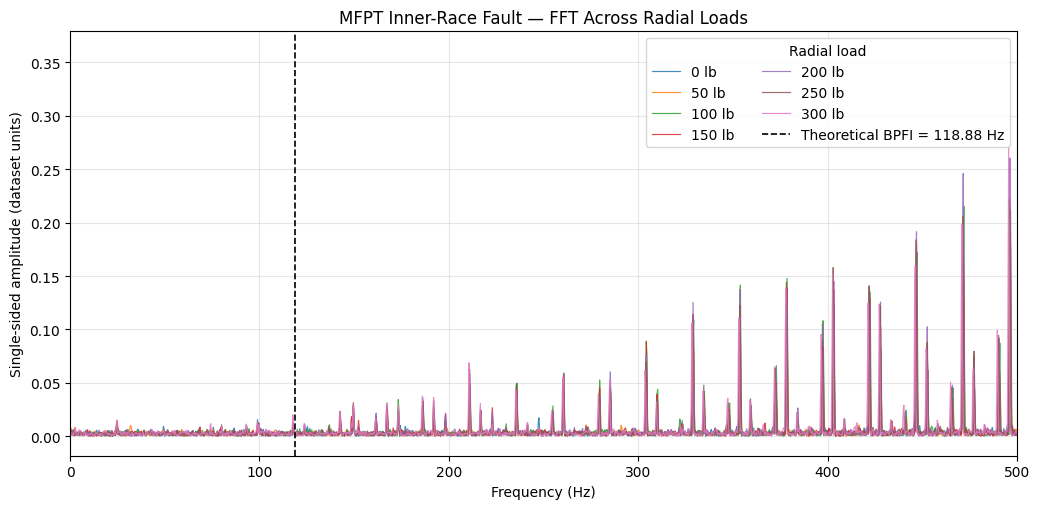

In [ ]:
OUTPUT_DIR = Path("MFPT_Report_Outputs")
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10.5, 5.2))
for filename, rec in sorted_by_load(inner_variable):
    x_demeaned, _, _ = preprocess_signal(rec.signal, normalization="none")
    freqs, amp = single_sided_amplitude_spectrum(
        x_demeaned, rec.sampling_rate, window="hann"
    )
    load = float(rec.metadata["load_lbs"])
    ax.plot(freqs, amp, linewidth=0.85, alpha=0.85, label=f"{load:g} lb")

shaft_rate = float(next(iter(inner_variable.values())).metadata["shaft_rate_hz"])
bpfi = kinematic_fault_frequencies(shaft_rate_hz=shaft_rate, geometry=MFPT_NICE)["BPFI_Hz"]
ax.axvline(bpfi, color="black", linestyle="--", linewidth=1.2,
           label=f"Theoretical BPFI = {bpfi:.2f} Hz")
ax.set_xlim(0, 500)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Single-sided amplitude (dataset units)")
ax.set_title("MFPT Inner-Race Fault — FFT Across Radial Loads")
ax.legend(title="Radial load", ncols=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "Fig_B1_MFPT_Inner_Race_FFT_Loads.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Fig. B2  MFPT outer race FFT across radial loads

The outer race series begins at 25 lb, unlike the inner race series, the supplied MFPT files contain no 0 lb outer-race record. The vertical line marks the ideal BPFO.

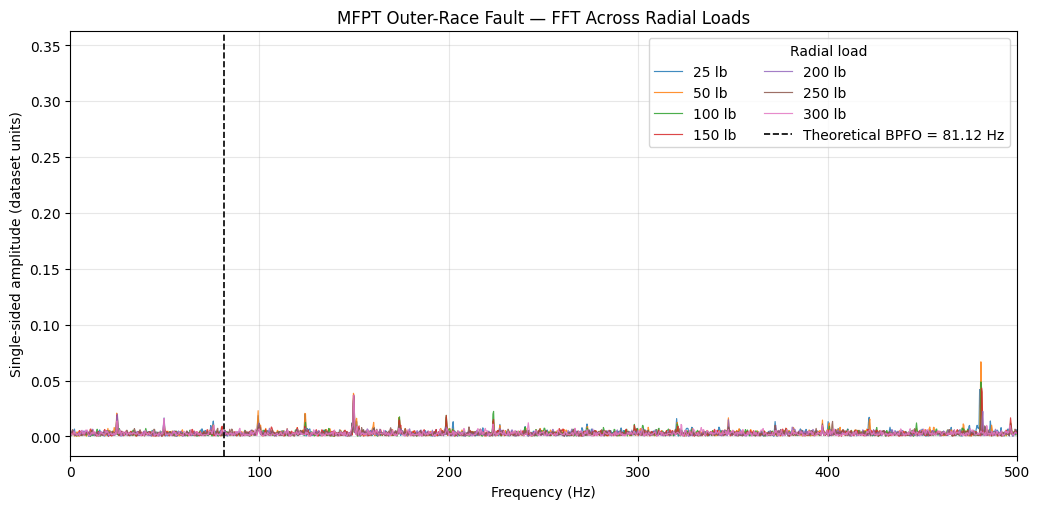

In [ ]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))
for filename, rec in sorted_by_load(outer_variable):
    x_demeaned, _, _ = preprocess_signal(rec.signal, normalization="none")
    freqs, amp = single_sided_amplitude_spectrum(
        x_demeaned, rec.sampling_rate, window="hann"
    )
    load = float(rec.metadata["load_lbs"])
    ax.plot(freqs, amp, linewidth=0.85, alpha=0.85, label=f"{load:g} lb")

shaft_rate = float(next(iter(outer_variable.values())).metadata["shaft_rate_hz"])
bpfo = kinematic_fault_frequencies(shaft_rate_hz=shaft_rate, geometry=MFPT_NICE)["BPFO_Hz"]
ax.axvline(bpfo, color="black", linestyle="--", linewidth=1.2,
           label=f"Theoretical BPFO = {bpfo:.2f} Hz")
ax.set_xlim(0, 500)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Single-sided amplitude (dataset units)")
ax.set_title("MFPT Outer-Race Fault — FFT Across Radial Loads")
ax.legend(title="Radial load", ncols=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "Fig_B2_MFPT_Outer_Race_FFT_Loads.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Fig. B3 RMS vibration amplitude across radial loads

RMS is calculated after subtracting the sample mean. The three healthy baseline recordings are repeated measurements at 270 lb, 97.656 kHz, and 6 s. Their mean and sample standard deviation are shown as a separate reference marker. The healthy reference is not a healthy load sweep and is not connected to the fault curves.

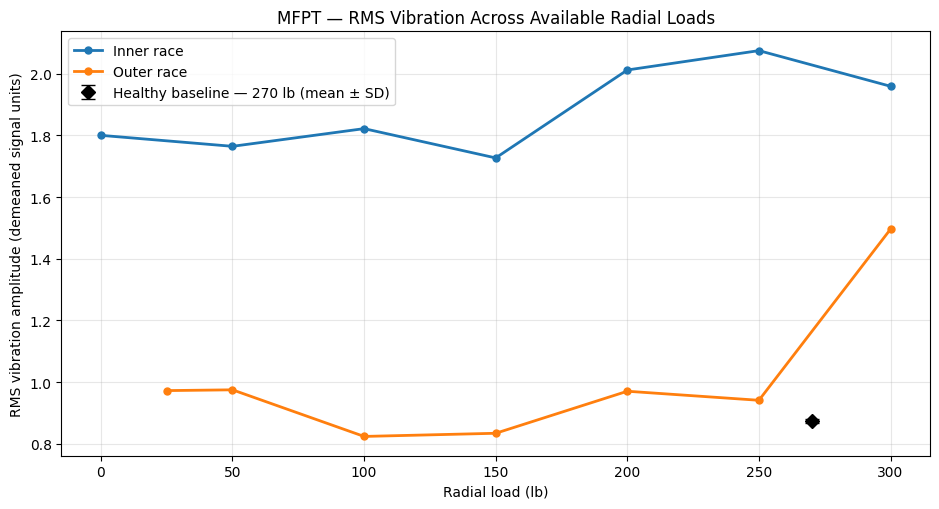

In [ ]:
fault_rows = mfpt_summary_df[
    mfpt_summary_df["Fault"].isin(["Inner race", "Outer race"])
    & np.isclose(mfpt_summary_df["Sampling_Rate_Hz"], 48828, atol=1)
].copy()
baseline_rows = mfpt_summary_df[
    (mfpt_summary_df["Fault"] == "Normal")
    & np.isclose(mfpt_summary_df["Load_lb"], 270)
].copy()

fig, ax = plt.subplots(figsize=(9.5, 5.2))
for fault in ["Inner race", "Outer race"]:
    subset = fault_rows[fault_rows["Fault"] == fault].sort_values("Load_lb")
    ax.plot(
        subset["Load_lb"], subset["RMS_Demeaned"],
        marker="o", linewidth=2, markersize=5, label=fault
    )

baseline_mean = baseline_rows["RMS_Demeaned"].mean()
baseline_std = baseline_rows["RMS_Demeaned"].std(ddof=1)
ax.errorbar(
    [270], [baseline_mean], yerr=[baseline_std],
    fmt="D", color="black", capsize=5, markersize=7,
    label="Healthy baseline — 270 lb (mean ± SD)"
)
ax.set_xlabel("Radial load (lb)")
ax.set_ylabel("RMS vibration amplitude (demeaned signal units)")
ax.set_title("MFPT — RMS Vibration Across Available Radial Loads")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "Fig_B3_MFPT_RMS_vs_Load.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Export the report figures and supporting tables


In [ ]:
# Export recording-level metadata/statistics and theoretical characteristic frequencies.
frequency_table = pd.DataFrame([{
    "Shaft_Rate_Hz": float(shaft_rate),
    "Shaft_RPM": float(kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["shaft_rpm"]),
    "BPFO_Hz": float(kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["BPFO_Hz"]),
    "BPFI_Hz": float(kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["BPFI_Hz"]),
    "BSF_Hz": float(kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["BSF_Hz"]),
    "FTF_Hz": float(kinematic_fault_frequencies(shaft_rate_hz=float(shaft_rate), geometry=MFPT_NICE)["FTF_Hz"]),
} for shaft_rate in sorted(mfpt_summary_df["Shaft_Rate_Hz"].unique())])

mfpt_summary_df.to_csv(TABLE_DIR / "MFPT_Recording_Metadata_and_Statistics.csv", index=False)
frequency_table.to_csv(TABLE_DIR / "MFPT_Kinematic_Frequency_Table.csv", index=False)

print("Saved report figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print(" -", p.name)
print("\nSaved supporting tables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print(" -", p.name)

display(frequency_table.round(4))

Saved report figures:
 - Fig_B1_MFPT_Inner_Race_FFT_Loads.png
 - Fig_B2_MFPT_Outer_Race_FFT_Loads.png
 - Fig_B3_MFPT_RMS_vs_Load.png

Saved supporting tables:
 - MFPT_Kinematic_Frequency_Table.csv
 - MFPT_Recording_Metadata_and_Statistics.csv


,Shaft_Rate_Hz,Shaft_RPM,BPFO_Hz,BPFI_Hz,BSF_Hz,FTF_Hz
0,25.0,1500.0,81.1245,118.8755,63.864,10.1406


In [ ]:
# Bundle only the three report figures and the two supporting CSV tables.
OUTPUT_ZIP = shutil.make_archive(
    "MFPT_Report_Outputs",
    "zip",
    root_dir=OUTPUT_DIR
)
print("Report-output archive:", OUTPUT_ZIP)
print("Included: 3 figures and 2 tables")

Report-output archive: /content/MFPT_Report_Outputs.zip
Included: 3 figures and 2 tables


## Notes

- The MFPT variable load inner race records cover 0–300 lb in 50 lb steps. The outer race records cover 25–300 lb, with the same 50 lb increments after 25 lb.
- All variable load fault records are 48.828 kHz and 3 s. The three healthy baseline repeats are 97.656 kHz and 6 s at 270 lb. Because sampling rates and record durations differ, the healthy baseline is included as a separate RMS reference only, it is not overlaid on the fault FFT curves.
- RMS describes overall signal amplitude, it is not by itself a fault detector.
- These are my baseline analyses. Resonance filtering, Hilbert envelope demodulation, SES, and adaptive thresholding are done by my other team members.